# Assignment 10
Muyuan Ma

In [1]:
# run this cell to install the fast parquet library
!pip install fastparquet

In [2]:
 # import all the libraries for this assignment
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

## 1. ( 10 pts) Include any previous data preparation steps, EDA and visualizations.

In [3]:
#let's load the data into a dataframe

tripdata_df = pd.read_parquet(path = 'https://d37ci6vzurychx.cloudfront.net/trip-data/green_tripdata_2020-02.parquet', #provide the URL to the data source
                      engine = 'fastparquet')

In [4]:
# identify the dimension of the data
print('dimension:' + str(tripdata_df.shape))

dimension:(398632, 20)


In [5]:
# look for the data type of each variable
print(tripdata_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398632 entries, 0 to 398631
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               398632 non-null  int64         
 1   lpep_pickup_datetime   398632 non-null  datetime64[ns]
 2   lpep_dropoff_datetime  398632 non-null  datetime64[ns]
 3   store_and_fwd_flag     317739 non-null  object        
 4   RatecodeID             317739 non-null  float64       
 5   PULocationID           398632 non-null  int64         
 6   DOLocationID           398632 non-null  int64         
 7   passenger_count        317739 non-null  float64       
 8   trip_distance          398632 non-null  float64       
 9   fare_amount            398632 non-null  float64       
 10  extra                  398632 non-null  float64       
 11  mta_tax                398632 non-null  float64       
 12  tip_amount             398632 non-null  floa

### Check Missing Values

In [6]:
# check the number of missing data for each column.
print(tripdata_df.isnull().sum())

VendorID                      0
lpep_pickup_datetime          0
lpep_dropoff_datetime         0
store_and_fwd_flag        80893
RatecodeID                80893
PULocationID                  0
DOLocationID                  0
passenger_count           80893
trip_distance                 0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
ehail_fee                398632
improvement_surcharge         0
total_amount                  0
payment_type              80893
trip_type                 80894
congestion_surcharge      80893
dtype: int64


In [7]:
# check the number of missing data for each row.
print(tripdata_df.isnull().sum(axis=1).sort_values(ascending = False))

398631    7
344706    7
344699    7
344700    7
344701    7
         ..
132875    1
132874    1
132873    1
132872    1
199316    1
Length: 398632, dtype: int64


### Check Invalid Data

In [8]:
# check every RatecodeID representing different locations of the end of the trip.
print(tripdata_df['RatecodeID'].value_counts(dropna=True))

1.0     309477
5.0       7246
2.0        620
4.0        263
3.0        130
99.0         2
6.0          1
Name: RatecodeID, dtype: int64


In [9]:
# check every VendorID representing different LPEP providers
print(tripdata_df['VendorID'].value_counts(dropna=True))

2    345899
1     52704
6        29
Name: VendorID, dtype: int64


In [10]:
# check whether there is any negative total amount in descending order. 
print(tripdata_df[tripdata_df.total_amount < 0]['total_amount'].value_counts(dropna=True))

-3.80     192
-4.30     174
-3.30     173
-4.80     128
-5.30     111
         ... 
-6.24       1
-85.30      1
-11.80      1
-14.30      1
-39.50      1
Name: total_amount, Length: 93, dtype: int64


There are invalid values. First, there's two values of 99 existing in RatecodeID variables. RatecodeID variables are expected to be integers between 1 and 6. 99 does not make any sense. Second, there's 29 values of 6 existing in VendorID variables. VendorID variables are expected to be only 1 or 2(representing two companies). 6 does not make any sense. Third, there're negative values in total_amount variable. Total_amount variable should have no negative value.

### Data Preparation

In [11]:
# delete ehail_fee column since there's no such variable in the data dictionary
# Then check the dimension to make sure it has been deleted.
tripdata_df.pop('ehail_fee')
print(tripdata_df.shape)

(398632, 19)


In [12]:
# delete congestion_surcharge since there's no such variable in the data dictionary
# Then check the dimension to make sure it has been deleted.
tripdata_df.pop('congestion_surcharge')
print(tripdata_df.shape)

(398632, 18)


In [13]:
# delete rows that has 4 or more missing data variable
tripdata_df = tripdata_df[tripdata_df.isnull().sum(axis=1) < 4]

In [14]:
# check what is the mode result of store_and_fwd_flag vairable
print(tripdata_df['store_and_fwd_flag'].value_counts(dropna=True))

N    316829
Y       910
Name: store_and_fwd_flag, dtype: int64


In [15]:
# give every missing data in store_and_fwd_flag vairable value of 'N'
# then set store_and_fwd_flag data type to str
tripdata_df.loc[tripdata_df['store_and_fwd_flag'].isna(), 'store_and_fwd_flag'] = 'N'
tripdata_df['store_and_fwd_flag'] = tripdata_df['store_and_fwd_flag'].astype('string')

In [16]:
# give every missing data in passenger_count variable a the median value 
# of the number of passanger
# Then set passenger_count data type to be interger
tripdata_df.loc[tripdata_df['passenger_count'].isna(), 'passenger_count'] = tripdata_df['passenger_count'].median()
tripdata_df['passenger_count']  = tripdata_df['passenger_count'].astype(int)

In [17]:
# check what is the mode value of RatecodeID column
print(tripdata_df['RatecodeID'].value_counts(dropna=True))

1.0     309477
5.0       7246
2.0        620
4.0        263
3.0        130
99.0         2
6.0          1
Name: RatecodeID, dtype: int64


In [18]:
# give every missing data in RatecodeID variable a mode value of the RatecodeID
# Then set RatecodeID data type to be interger
tripdata_df.loc[tripdata_df['RatecodeID'].isna(), 'RatecodeID'] = 1.0
tripdata_df['RatecodeID']  = tripdata_df['RatecodeID'].astype(int)

In [19]:
# check what is the mode value in payment_type column
print(tripdata_df['payment_type'].value_counts(dropna=True))

1.0    176530
2.0    138849
3.0      1767
4.0       579
5.0        14
Name: payment_type, dtype: int64


In [20]:
# give every missing data in payment_type variable a mode value of the payment_type
# Then set payment_type data type to be interger
tripdata_df.loc[tripdata_df['payment_type'].isna(), 'payment_type'] = 1.0
tripdata_df['payment_type'] = tripdata_df['payment_type'].astype(int)

In [21]:
# check what is the mode value in trip_type column
print(tripdata_df['trip_type'].value_counts(dropna=True))

1.0    310466
2.0      7272
Name: trip_type, dtype: int64


In [22]:
# give every missing data in trip_type variable a mode value of the trip_type
# Then set trip_data data type to be interger
tripdata_df.loc[tripdata_df['trip_type'].isna(), 'trip_type'] = 1.0
tripdata_df['trip_type'] = tripdata_df['trip_type'].astype(int)

In [23]:
# change all data that has negative value in total amount variable to the mean value.
tripdata_df.loc[tripdata_df['total_amount'] < 0, 'total_amount'] = tripdata_df['total_amount'].mean()

In [24]:
# change all data that equals to 99 in RatecodeID variable to 1(mode value)
tripdata_df.loc[tripdata_df['RatecodeID'] == 99, 'RatecodeID'] = 1

In [25]:
# change all data that equals to 6 in VendorID variable to 2(mode value)
tripdata_df.loc[tripdata_df['VendorID'] == 6, 'VendorID'] = 2

In [26]:
# delete all duplicate values
tripdata_df.drop_duplicates(inplace=True)

In [27]:
# check data type
print(tripdata_df.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 317739 entries, 0 to 317738
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               317739 non-null  int64         
 1   lpep_pickup_datetime   317739 non-null  datetime64[ns]
 2   lpep_dropoff_datetime  317739 non-null  datetime64[ns]
 3   store_and_fwd_flag     317739 non-null  string        
 4   RatecodeID             317739 non-null  int32         
 5   PULocationID           317739 non-null  int64         
 6   DOLocationID           317739 non-null  int64         
 7   passenger_count        317739 non-null  int32         
 8   trip_distance          317739 non-null  float64       
 9   fare_amount            317739 non-null  float64       
 10  extra                  317739 non-null  float64       
 11  mta_tax                317739 non-null  float64       
 12  tip_amount             317739 non-null  floa

In [28]:
# check whether every value is not-null
print(tripdata_df.isnull().sum())

VendorID                 0
lpep_pickup_datetime     0
lpep_dropoff_datetime    0
store_and_fwd_flag       0
RatecodeID               0
PULocationID             0
DOLocationID             0
passenger_count          0
trip_distance            0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
payment_type             0
trip_type                0
dtype: int64


In [29]:
# check the dimension
print(tripdata_df.shape)

(317739, 18)


In [30]:
# check whether RatecodeID has any invalid value
print(tripdata_df['RatecodeID'].value_counts(dropna=True))

1    309479
5      7246
2       620
4       263
3       130
6         1
Name: RatecodeID, dtype: int64


1, 2, 3, 4, 5, and 6 are all acceptable values. So there's no invalid values here.

In [31]:
# check whether VendorID has any invalid value
print(tripdata_df['VendorID'].value_counts(dropna=True))

2    265035
1     52704
Name: VendorID, dtype: int64


1 and 2 are all acceptable values. So there's no invalid values here.

In [32]:
# check whether total_amount has any invalid value
print(tripdata_df[tripdata_df.total_amount < 0]['total_amount'].value_counts(dropna=True))

Series([], Name: total_amount, dtype: int64)


There's no values exists by selecting the negative values in total_amount column. So every values are acceptable.

### Data Analysis

In [33]:
# print the datasets with total_amount and trip_distance variables that has the biggest total_amount
print(tripdata_df.sort_values('total_amount').tail(1).loc[:, ['total_amount','trip_distance']])

       total_amount  trip_distance
71544         651.5            1.1


In [34]:
# print the datasets with total_amount and trip_distance variables that has the smallest total_amount
print(tripdata_df.sort_values('total_amount').head(1).loc[:, ['total_amount','trip_distance']])

        total_amount  trip_distance
114937           0.0            0.0


The most expensive trip is number 71544, costing 651.5 US dollars, traveling 1.1 miles. This datum does not make too much sense. It's not common to spend 600s US dollars in just about 1 miles by cab. The least expensive trip is number 114937, costing 0.0 US dollar, traveling 0.0 mile. This datum does make sense. It's common to sometimes cancel the trip before starting, riding 0 miles and cost 0 dollar. 

### Visualization

Create bar charts that show the most common way that New Yorkers request/hail a cab and the most 5 common drop-off locations.

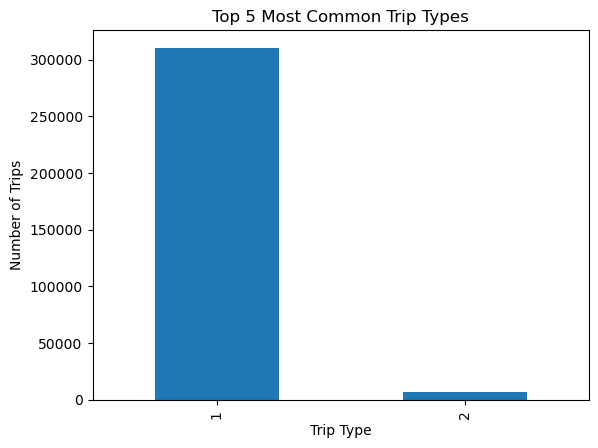

In [35]:
# Get the top 5 most common trip types
top_5_common_way = tripdata_df['trip_type'].value_counts().head()


# Create a bar plot
ax = top_5_common_way.plot(kind='bar')

# Add titles and axis names
ax.set_title('Top 5 Most Common Trip Types')
ax.set_xlabel('Trip Type')
ax.set_ylabel('Number of Trips')

# Display the plot
plt.show()

The top most common way that New Yorkers request a cab is by street-hailing. The second most common way is by dispatching. From the chart, we can see bar 1 is much more high than bar 2. This represents that New Yorkers like to request a cab by street-hailing much more than by dispatching.

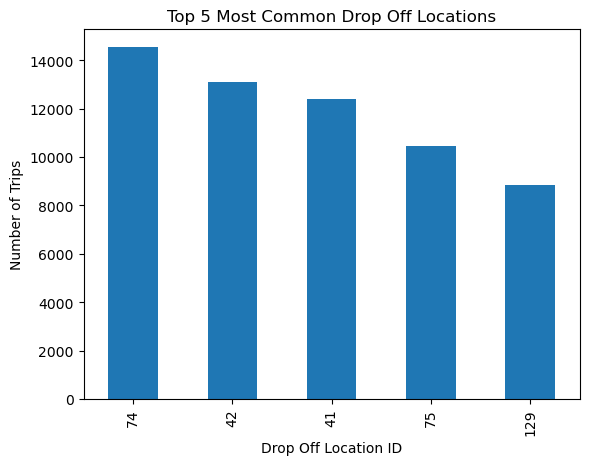

In [36]:
# Get the top 5 most common drop off locations
top_5_drop_off_location = tripdata_df['DOLocationID'].value_counts().head()

# Create a bar plot
ax = top_5_drop_off_location.plot(kind='bar')

# Add titles and axis names
ax.set_title('Top 5 Most Common Drop Off Locations')
ax.set_xlabel('Drop Off Location ID')
ax.set_ylabel('Number of Trips')

# Display the plot
plt.show()

The top most common drop-off location is number 75. The second most common drop-off location is number 42. The third most common drop-off location is number 41. The fourth most common drop-off location is number 75. The fifth most common drop-off location is number 129. From the chart, bars are decreasing in a steady rate, meaning there's not a super common drop-off location. The second most common drop-off location is just slightly less popular than the top most common drop-off location.

Based on the prelimimary analysis, I think this data is not a viable source that can be used to understand New Yorker's behavior of using these cabs. Althogh The bar charts showing the way of New Yorkers request a cab and the top 5 most common destination let this dataset seems to be reasonable, it still cannot account for most expensive trip one which generate 600 dollar by riding 1 miles without adding up the tip(described in data dictionary). Besides, there's lots of empty and invalid data exists in this dataset that has been removed before, making this whole dataset less credible. It has to be some errors exist when collecting the data.

#### Those all are my previous data preparation steps, EDA and visualizations

## 2. (5 pts) Select the required features to build your model based on the insights from your EDA. Briefly explain the reason for the features that you selected. Ensure that you encode any categorical features.

In [37]:
tripdata_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 317739 entries, 0 to 317738
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               317739 non-null  int64         
 1   lpep_pickup_datetime   317739 non-null  datetime64[ns]
 2   lpep_dropoff_datetime  317739 non-null  datetime64[ns]
 3   store_and_fwd_flag     317739 non-null  string        
 4   RatecodeID             317739 non-null  int32         
 5   PULocationID           317739 non-null  int64         
 6   DOLocationID           317739 non-null  int64         
 7   passenger_count        317739 non-null  int32         
 8   trip_distance          317739 non-null  float64       
 9   fare_amount            317739 non-null  float64       
 10  extra                  317739 non-null  float64       
 11  mta_tax                317739 non-null  float64       
 12  tip_amount             317739 non-null  floa

I decide to let PULocationID, DOLocationID, ratecodeID, trip_distance, fare_amount, and total_amount to be the input feature. 
Based on my own experience, I think the the tip amount is based on the distance, fareamount, and total-amount because a passanger would like to pay more with more distance, fareamount, or total-amount. Also, the pick-up and drop-off place matter because passangers picked from different neighbourhoods and the place they are going may classify them as rich or have low income, which gives the different amount of tips.

In [38]:
# change RateCodeID type to categorical
tripdata_df['RatecodeID'] = tripdata_df['RatecodeID'].astype('category')

In [39]:
#encode the categorical feature
tripdata_df = pd.get_dummies(tripdata_df, drop_first=True) #drop one of the encoded gender columns

In [40]:
tripdata_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 317739 entries, 0 to 317738
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               317739 non-null  int64         
 1   lpep_pickup_datetime   317739 non-null  datetime64[ns]
 2   lpep_dropoff_datetime  317739 non-null  datetime64[ns]
 3   PULocationID           317739 non-null  int64         
 4   DOLocationID           317739 non-null  int64         
 5   passenger_count        317739 non-null  int32         
 6   trip_distance          317739 non-null  float64       
 7   fare_amount            317739 non-null  float64       
 8   extra                  317739 non-null  float64       
 9   mta_tax                317739 non-null  float64       
 10  tip_amount             317739 non-null  float64       
 11  tolls_amount           317739 non-null  float64       
 12  improvement_surcharge  317739 non-null  floa

Now confirm that RatecodeID has been encoded.

Overhere I change the data type of ratecodeID to categorical and encoding it as dummy variables. This allows us to include them as input features in the model.

## 3. (5 pts) Partition the data into train/test split.

In [41]:
# create input features DataFrame
X = tripdata_df[['PULocationID', 'DOLocationID', 'RatecodeID_2', 'RatecodeID_3', 'RatecodeID_4', 'RatecodeID_5', 'RatecodeID_6', 'trip_distance', 'fare_amount', 'total_amount']]

# create label DataFrame
y = tripdata_df['tip_amount']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Now the data has been splited

## 4. (15 pts) Build a model that predicts the tip amount.

I choose regression model. The reason to choose a regression model to predict the tip amount in this case is because the tip amount is a continuous variable. Regression models are appropriate for predicting continuous variables, as they model the relationship between the input features and the output variable as a continuous function.

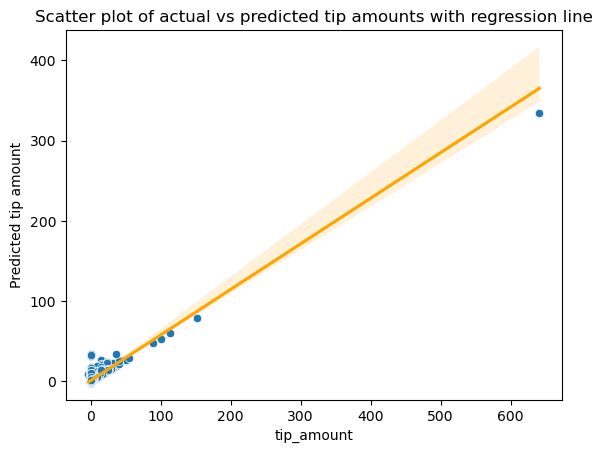

In [42]:
# create a linear regression object
model = LinearRegression()

# fit the model using the training data
model.fit(X_train, y_train)
# predict on the test data
y_pred = model.predict(X_test)

# create a scatter plot of actual tip amounts vs predicted tip amounts
sns.scatterplot(x=y_test, y=y_pred)
plt.xlabel("Actual tip amount")
plt.ylabel("Predicted tip amount")
plt.title("Scatter plot of actual vs predicted tip amounts with regression line")

# add a regression line to the plot
sns.regplot(x=y_test, y=y_pred, scatter=False, color="orange")

plt.show()

I make a linear regression model to the training data, makes predictions on the test data, and visualizes the results using a scatter plot with a regression line. The scatter plot and regression line can help visualize how well the model is able to predict the tip amounts, and whether there is a linear relationship between the predicted and actual tip amounts.

## 5. (5 pts) Evaluate the predictions from your model and comment on the results. Ensure that you choose the correct metric. Remember that we evaluate models differently depending on the task, i.e. classification or regression.

In [43]:
# calculate the R-squared value
r_squared = model.score(X_test, y_test)

print("R-squared value: {:.2f}".format(r_squared))

R-squared value: 0.73


The R-squared value represents the proportion of variance in the target variable that can be explained by the input features.
The scatter plot of the actual versus predicted tip amounts allowed me to visually inspect how well the model was able to predict the tip amounts.

the R-squared value for the model is 0.73, indicating that the input features explain 73% of the variance in the tip amounts. This means that the model is able to capture a large proportion of the relationships between the input features and the tip amounts.

## 6. (10 pts) How do you feel about the model? Does it do a good job of predicting the tip_amount?

Based on the R-squared value of 0.73, it seems that the model is doing a good job of predicting the tip amount. The R-squared value indicates that the input features explain 73% of the variance in the tip amounts, which is a relatively high proportion.

Additionally, when visualizing the predicted versus actual tip amounts using a scatter plot, we can see that the model generally predicts higher tip amounts for higher actual tip amounts, and the points are clustered more closely around a straight line. This suggests that the model is performing well and is able to accurately predict the tip amounts based on the input features.

## 7. (+5 bonus points) The Random forest has a method that returns the importance of each feature in your model. Can you find out which of your selected features were the most important when making the predictions?

In [44]:
# create a random forest regression object
rf = RandomForestRegressor()

# fit the model using the training data
rf.fit(X_train, y_train)

# get the feature importances
importances = rf.feature_importances_

# sort the features by importance in descending order
indices = np.argsort(importances)[::-1]

# print the feature ranking
print("Feature ranking:")

for f in range(X.shape[1]):
    print("%d. %s (%f)" % (f + 1, X.columns[indices[f]], importances[indices[f]]))

Feature ranking:
1. total_amount (0.550738)
2. fare_amount (0.370514)
3. trip_distance (0.029949)
4. DOLocationID (0.024488)
5. PULocationID (0.015307)
6. RatecodeID_5 (0.004540)
7. RatecodeID_2 (0.002839)
8. RatecodeID_4 (0.001166)
9. RatecodeID_3 (0.000458)
10. RatecodeID_6 (0.000000)


In this case I list all the importance of each feature, and sort them by descending order of the importance. The result shows that total_amount has the greatest importance when making the predictions of tip amount.